<a href="https://colab.research.google.com/github/JonerciJon/CSST106/blob/main/PCA_in_CV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading AT&T Olivetti Faces dataset...
downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data

--- Task 1: Dataset Summary ---
n_samples : 400
n_features: 4096 (64x64 pixels)
n_classes : 40 (10 images per subject)
Train samples: 320 | Test samples: 80

--- Task 2: Fitting PCA (n_components=100, whiten=True) ---
PCA fit completed in 1.124s
X_train_pca shape: (320, 100)
X_test_pca shape : (80, 100)

--- Task 3: Visualizing Eigenfaces ---


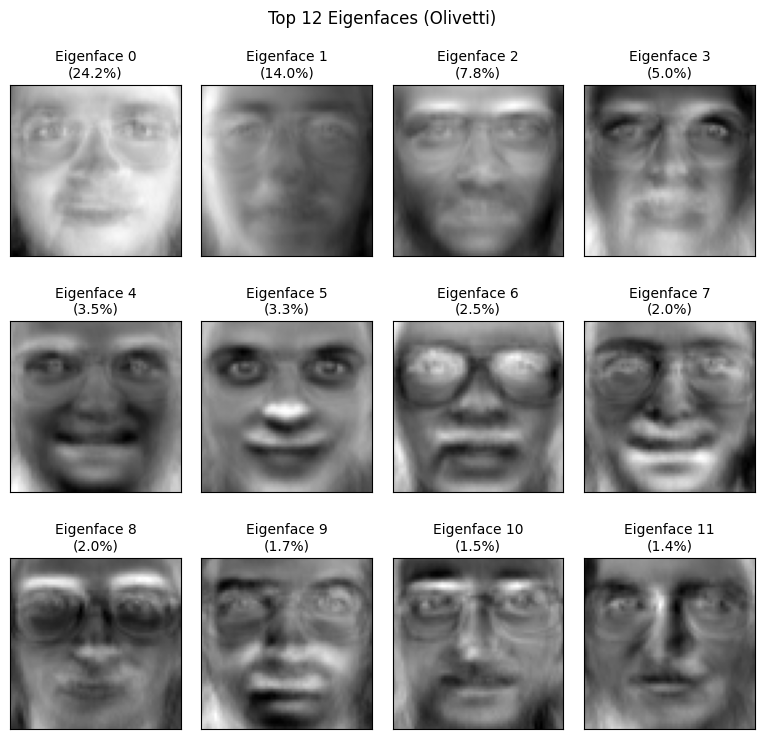

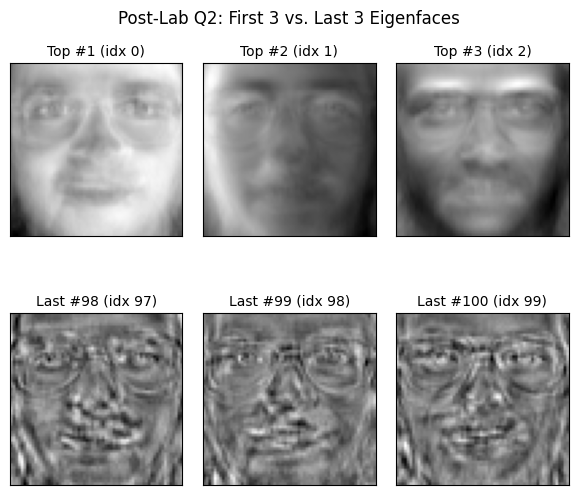


--- Task 4: Training SVM on PCA Projections ---
SVM fit completed in 0.084s
Test Set Accuracy: 0.9750 (97.50%)

Classification Report:
              precision    recall  f1-score   support

  Subject 00       1.00      1.00      1.00         2
  Subject 01       1.00      1.00      1.00         2
  Subject 02       0.50      0.50      0.50         2
  Subject 03       1.00      1.00      1.00         2
  Subject 04       1.00      1.00      1.00         2
  Subject 05       1.00      1.00      1.00         2
  Subject 06       1.00      1.00      1.00         2
  Subject 07       1.00      1.00      1.00         2
  Subject 08       1.00      1.00      1.00         2
  Subject 09       1.00      1.00      1.00         2
  Subject 10       1.00      1.00      1.00         2
  Subject 11       1.00      1.00      1.00         2
  Subject 12       0.67      1.00      0.80         2
  Subject 13       1.00      1.00      1.00         2
  Subject 14       1.00      1.00      1.00         2

In [2]:
# ==============================================================================
# CSST106 - Laboratory Exercise No. 5: Facial Recognition using PCA (Eigenfaces)
# Alternative Dataset: AT&T Olivetti Faces (400 images, 40 subjects, 64x64 px)
# ==============================================================================

import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score


# ------------------------------------------------------------------------------
# Helper function to display portrait grids
# ------------------------------------------------------------------------------
def plot_gallery(images, titles, h, w, n_row=3, n_col=4, suptitle=None):
    """Helper function to plot a gallery of portraits."""
    plt.figure(figsize=(1.9 * n_col, 2.5 * n_row))
    plt.subplots_adjust(bottom=0.02, left=0.01, right=0.99, top=0.88, hspace=0.38, wspace=0.12)
    if suptitle:
        plt.suptitle(suptitle, fontsize=12)
    total = min(n_row * n_col, len(images))
    for i in range(total):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i], cmap=plt.cm.gray)
        plt.title(titles[i], size=10)
        plt.xticks(())
        plt.yticks(())
    plt.show()


# ==============================================================================
# TASK 1: Data Acquisition and Preprocessing (Olivetti Faces Dataset)
# ==============================================================================
print("Loading AT&T Olivetti Faces dataset...")
olivetti = fetch_olivetti_faces(shuffle=True, random_state=42)

n_samples, h, w = olivetti.images.shape
X = olivetti.data
y = olivetti.target
n_classes = len(np.unique(y))
target_names = np.array([f"Subject {i:02d}" for i in range(n_classes)])

print("\n--- Task 1: Dataset Summary ---")
print(f"n_samples : {n_samples}")
print(f"n_features: {X.shape[1]} ({h}x{w} pixels)")
print(f"n_classes : {n_classes} (10 images per subject)")

# Stratified 80/20 split (8 train images & 2 test images per subject)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train samples: {X_train.shape[0]} | Test samples: {X_test.shape[0]}")


# ==============================================================================
# TASK 2: Computing the Principal Components (Eigenfaces)
# ==============================================================================
n_components = 100  # 100 components works well for 320 training faces
print(f"\n--- Task 2: Fitting PCA (n_components={n_components}, whiten=True) ---")
t0 = time.time()

pca = PCA(n_components=n_components, svd_solver="randomized", whiten=True, random_state=42)
pca.fit(X_train)

print(f"PCA fit completed in {time.time() - t0:.3f}s")

X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

print(f"X_train_pca shape: {X_train_pca.shape}")
print(f"X_test_pca shape : {X_test_pca.shape}")


# ==============================================================================
# TASK 3: Visualizing the Eigenfaces
# ==============================================================================
print("\n--- Task 3: Visualizing Eigenfaces ---")
eigenfaces = pca.components_.reshape((n_components, h, w))

# First 12 Eigenfaces
first_12_titles = [f"Eigenface {i}\n({pca.explained_variance_ratio_[i]*100:.1f}%)" for i in range(12)]
plot_gallery(eigenfaces[:12], first_12_titles, h, w, n_row=3, n_col=4, suptitle="Top 12 Eigenfaces (Olivetti)")

# Post-Lab Q2: First 3 vs. Last 3 Eigenfaces
first_and_last_6 = np.vstack([eigenfaces[:3], eigenfaces[-3:]])
fl_titles = (
    [f"Top #{i+1} (idx {i})" for i in range(3)]
    + [f"Last #{n_components-2+i} (idx {n_components-3+i})" for i in range(3)]
)
plot_gallery(
    first_and_last_6, fl_titles, h, w, n_row=2, n_col=3,
    suptitle="Post-Lab Q2: First 3 vs. Last 3 Eigenfaces"
)


# ==============================================================================
# TASK 4: Face Recognition in the Reduced Space (SVM Classifier)
# ==============================================================================
print("\n--- Task 4: Training SVM on PCA Projections ---")
t0 = time.time()

clf = SVC(kernel="rbf", class_weight="balanced", C=10.0, gamma="scale", random_state=42)
clf.fit(X_train_pca, y_train)

print(f"SVM fit completed in {time.time() - t0:.3f}s")

y_pred = clf.predict(X_test_pca)
acc = accuracy_score(y_test, y_pred)
print(f"Test Set Accuracy: {acc:.4f} ({acc*100:.2f}%)\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=target_names, zero_division=0))


# ==============================================================================
# POST-LAB ANALYSIS: Cumulative Variance (Q1) & Failure Analysis (Q4)
# ==============================================================================
cum_var = np.cumsum(pca.explained_variance_ratio_)